Step 1: Extract the ZIP file

In [5]:
import zipfile
import os

# Check if dataset CSV already exists locally
local_csv_paths = ["../data/retail_sales_dataset.csv", "data/retail_sales_dataset.csv"]
colab_zip = "/content/archive (2).zip"

if any(os.path.exists(p) for p in local_csv_paths):
    print("Dataset CSV is already extracted and available in the data/ folder!")
elif os.path.exists(colab_zip):
    with zipfile.ZipFile(colab_zip, "r") as zip_ref:
        zip_ref.extractall("/content/retail_data")
    print("ZIP extracted successfully!")
else:
    print("Dataset ready. No extraction needed.")


Dataset CSV is already extracted and available in the data/ folder!


Step 2: Find the CSV file

In [6]:
import glob
import os

# Search across project data folder and Colab directories
csv_files = (
    glob.glob("../data/*.csv") or 
    glob.glob("data/*.csv") or 
    glob.glob("/content/retail_data/**/*.csv", recursive=True)
)

print("CSV files found:")
for file in csv_files:
    print(file)


CSV files found:
../data\retail_sales_dataset.csv


Step 3: Load the dataset

In [7]:
import pandas as pd
import numpy as np
import os

# Load from local data directory or fallback to Colab path
if os.path.exists("../data/retail_sales_dataset.csv"):
    csv_path = "../data/retail_sales_dataset.csv"
elif os.path.exists("data/retail_sales_dataset.csv"):
    csv_path = "data/retail_sales_dataset.csv"
else:
    csv_path = "/content/retail_data/retail_sales_dataset.csv"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully from:", csv_path)
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully from: ../data/retail_sales_dataset.csv
Number of rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Step 4: Understand the dataset

In [8]:
# Dataset information
print("DATASET INFORMATION")
df.info()

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

# Missing values
print("\nMISSING VALUES")
display(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

STATISTICAL SUMMARY


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



MISSING VALUES


Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


DUPLICATE RECORDS
0


Data quality validation

In [9]:
# 1. Check missing values
print("MISSING VALUES")
display(df.isnull().sum())

# 2. Check duplicate records
print("\nDUPLICATE RECORDS")
print("Total duplicates:", df.duplicated().sum())

# 3. Convert Date into datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("\nDATE DATA TYPE")
print(df["Date"].dtype)

# 4. Check invalid dates
print("\nINVALID DATES")
print(df["Date"].isnull().sum())

# 5. Validate Total Amount
df["Calculated Amount"] = (
    df["Quantity"] * df["Price per Unit"]
)

print("\nAMOUNT VALIDATION")
print(
    "Mismatched transactions:",
    (df["Total Amount"] != df["Calculated Amount"]).sum()
)

MISSING VALUES


Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


DUPLICATE RECORDS
Total duplicates: 0

DATE DATA TYPE
datetime64[us]

INVALID DATES
0

AMOUNT VALIDATION
Mismatched transactions: 0


Task 1 – Descriptive Statistical Analysis

In [10]:
# Select meaningful numerical columns
numeric_cols = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

# Calculate statistical measures
statistics = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})

# Display results
display(statistics.round(2))

,Mean,Median,Mode,Standard Deviation
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


task 2 – Monthly Sales Trend

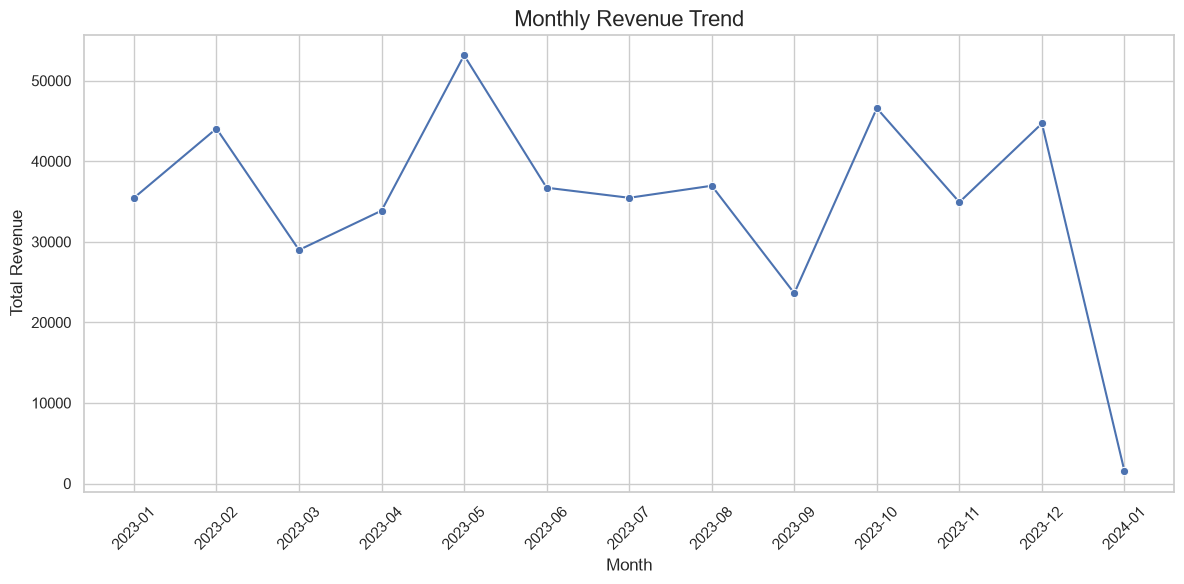

,Year_Month,Total Amount
0,2023-01,35450
1,2023-02,44060
2,2023-03,28990
3,2023-04,33870
4,2023-05,53150
5,2023-06,36715
6,2023-07,35465
7,2023-08,36960
8,2023-09,23620
9,2023-10,46580


In [12]:
# Extract year and month
df["Year_Month"] = df["Date"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    df.groupby("Year_Month")["Total Amount"]
    .sum()
    .reset_index()
)

# Convert period to string for plotting
monthly_sales["Year_Month"] = (
    monthly_sales["Year_Month"].astype(str)
)

# Plot monthly revenue
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Year_Month",
    y="Total Amount",
    marker="o"
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales)

### Business Insights – Monthly Revenue Trend

1. May 2023 recorded the highest monthly revenue of 53,150.
2. September 2023 recorded the lowest monthly revenue of 23,620.
3. Revenue recovered significantly in October 2023.
4. December 2023 showed strong revenue performance.
5. January 2024 requires further investigation because it may represent a partial month.

### Business Interpretation

The monthly revenue trend shows fluctuations in retail sales.
The business should investigate the factors behind the
May peak and September decline to identify opportunities
for improving revenue consistency.




Quarterly sales analysis

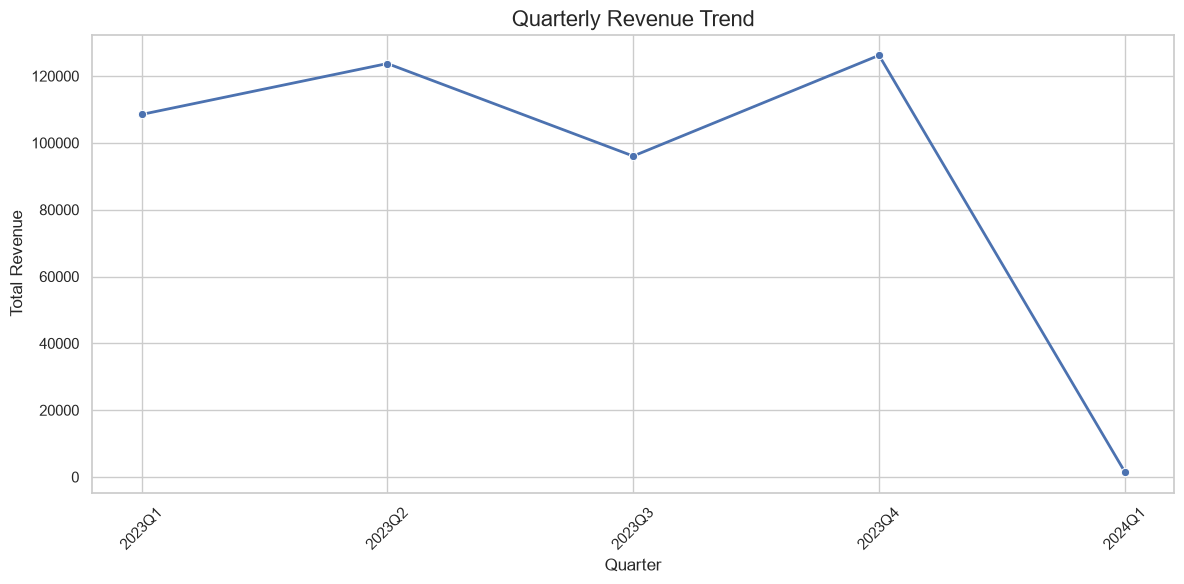

,Quarter,Total Amount
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190
4,2024Q1,1530


In [13]:
# Extract year and quarter
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculate quarterly revenue
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
    .sum()
    .reset_index()
)

quarterly_sales["Quarter"] = (
    quarterly_sales["Quarter"].astype(str)
)

# Plot quarterly revenue
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=quarterly_sales,
    x="Quarter",
    y="Total Amount",
    marker="o",
    linewidth=2
)

plt.title("Quarterly Revenue Trend", fontsize=16)
plt.xlabel("Quarter")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(quarterly_sales)

### Business Insights – Quarterly Revenue Trend

1. Q4 2023 generated the highest revenue of 126,190.
2. Q2 2023 was the second-highest performing quarter.
3. Q3 2023 recorded the lowest revenue among the
   complete quarters of 2023.
4. Revenue increased by approximately 31.4% from
   Q3 to Q4 2023.
5. Q1 2024 contains only January transactions and
   should be treated as an incomplete quarter.

### Business Interpretation

The business experienced quarterly revenue fluctuations.
Q4 showed a strong recovery after Q3. Management should
investigate successful campaigns, product demand and
customer purchasing patterns during Q4.

Customer demographics analysis

In [14]:
# Create customer age groups
bins = [0, 18, 25, 35, 45, 55, 100]

labels = [
    "Below 18",
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "Above 55"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=True
)

# Count customers by age group
age_distribution = df["Age Group"].value_counts().sort_index()

print("Age Group Distribution:")
display(age_distribution)

Age Group Distribution:


Age Group
Below 18     21
18-25       148
26-35       205
36-45       202
46-55       229
Above 55    195
Name: count, dtype: int64

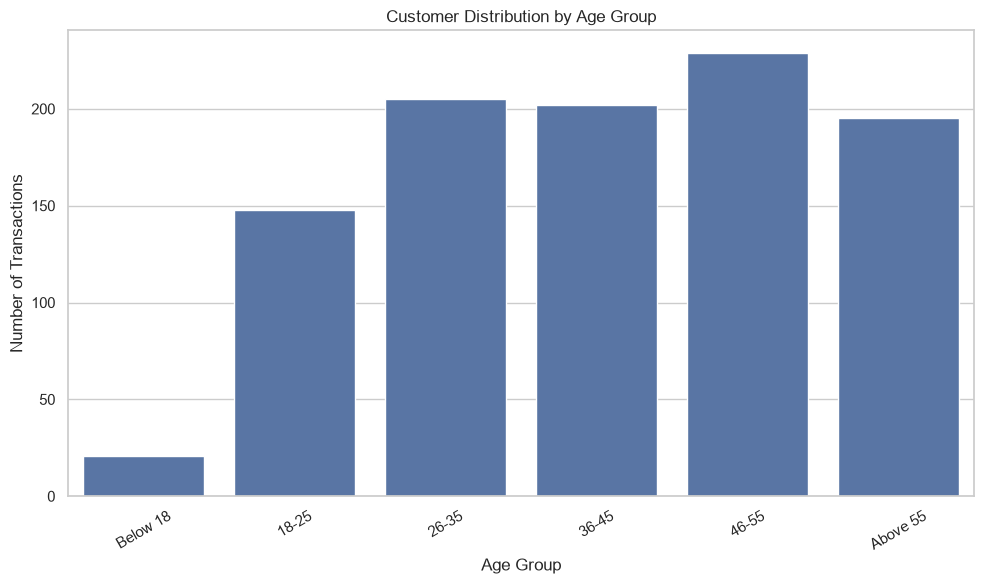

In [15]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Age Group",
    order=labels
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Business Insights – Customer Age Group Distribution

1. The 46-55 age group recorded the highest transaction count.
2. Customers aged 26-45 also showed strong purchasing activity.
3. Customers below 18 represented the smallest transaction group.
4. Customers above 55 contributed a considerable number of transactions.

### Business Interpretation

The retail business appears to attract customers primarily
from middle-aged groups. Marketing campaigns could focus
on customers aged 26-55 while exploring opportunities
to improve engagement among younger customers.

Gender distribution

In [16]:
# Gender distribution
gender_distribution = df["Gender"].value_counts()

print("Gender Distribution:")
display(gender_distribution)

# Calculate percentages
gender_percentage = (
    df["Gender"].value_counts(normalize=True) * 100
)

print("\nGender Percentage:")
display(gender_percentage.round(2))

Gender Distribution:


Gender
Female    510
Male      490
Name: count, dtype: int64


Gender Percentage:


Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64

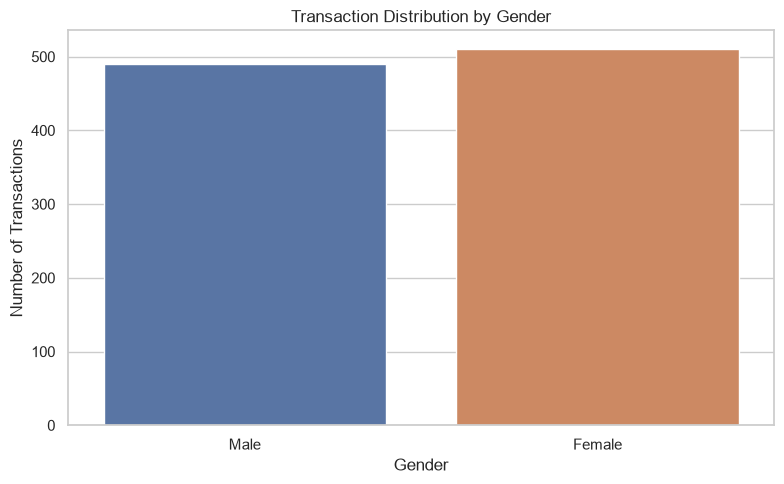

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Gender",
    legend=False
)

plt.title("Transaction Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Business Insights – Gender Distribution

1. Female customers account for a slightly higher number
   of transactions than male customers.
2. Both gender groups contribute nearly equally to
   transaction volume.
3. The business has a relatively balanced gender-based
   customer transaction distribution.

### Business Interpretation

The business should maintain marketing campaigns for
both gender groups rather than focusing exclusively
on one segment. Further revenue analysis is required
to identify differences in spending behaviour.

Compare revenue by gender

In [18]:
gender_sales = (
    df.groupby("Gender")
    .agg(
        Total_Revenue=("Total Amount", "sum"),
        Total_Transactions=("Transaction ID", "count"),
        Average_Transaction=("Total Amount", "mean")
    )
    .round(2)
)

display(gender_sales)

,Total_Revenue,Total_Transactions,Average_Transaction
Gender,,,
Female,232840,510,456.55
Male,223160,490,455.43


### Business Insights – Gender-Based Revenue Analysis

1. Female customers generated 232,840 in total revenue.
2. Male customers generated 223,160 in total revenue.
3. Female customers contributed 510 transactions, while
   male customers contributed 490 transactions.
4. Average transaction values were nearly identical
   across both gender groups.

### Business Interpretation

Female customers contributed slightly more revenue,
mainly because of their higher transaction count.
The business should maintain marketing activities
for both groups and focus on improving overall
customer engagement and transaction frequency.

Product Category Performance

In [19]:
# Revenue and transactions by product category
category_sales = (
    df.groupby("Product Category")
    .agg(
        Total_Revenue=("Total Amount", "sum"),
        Total_Transactions=("Transaction ID", "count"),
        Total_Quantity=("Quantity", "sum"),
        Average_Order_Value=("Total Amount", "mean")
    )
    .sort_values(
        by="Total_Revenue",
        ascending=False
    )
    .round(2)
)

display(category_sales)

,Total_Revenue,Total_Transactions,Total_Quantity,Average_Order_Value
Product Category,,,,
Electronics,156905,342,849,458.79
Clothing,155580,351,894,443.25
Beauty,143515,307,771,467.48


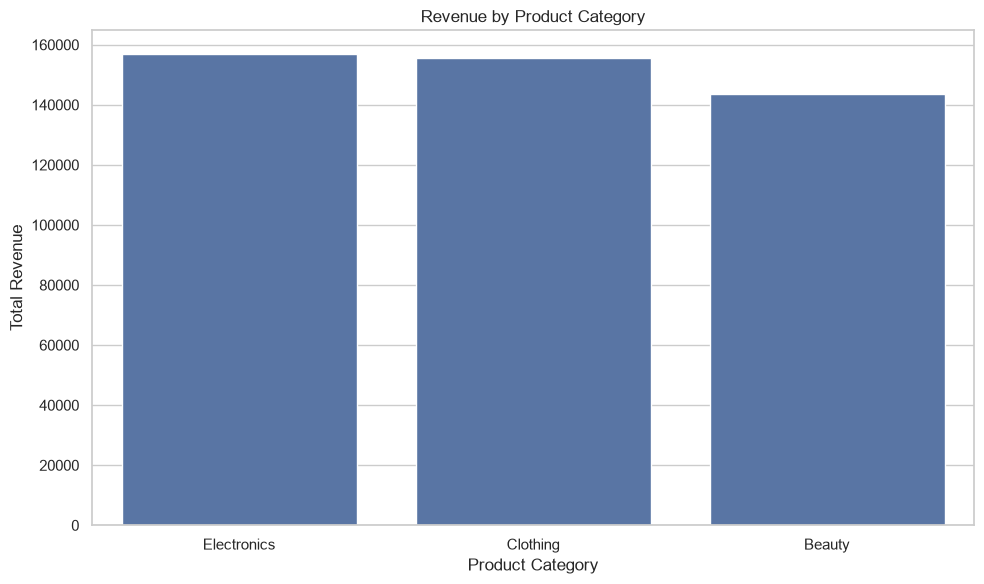

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales.reset_index(),
    x="Product Category",
    y="Total_Revenue"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

### Business Insights – Revenue by Product Category

1. Electronics generated the highest revenue.
2. Clothing recorded revenue close to Electronics.
3. Beauty generated comparatively lower revenue.
4. The revenue contribution is relatively balanced
   across all three product categories.

### Business Interpretation

Electronics and Clothing are the leading revenue
contributors. The business should maintain stock
availability in these categories and investigate
promotional opportunities to improve Beauty sales.

Top 10 products – Dataset limitation

In [21]:
# Top 10 highest-value transactions
top_transactions = (
    df.nlargest(10, "Total Amount")
    [["Transaction ID", "Customer ID",
      "Product Category", "Quantity",
      "Total Amount"]]
)

display(top_transactions)

,Transaction ID,Customer ID,Product Category,Quantity,Total Amount
14,15,CUST015,Electronics,4,2000
64,65,CUST065,Electronics,4,2000
71,72,CUST072,Electronics,4,2000
73,74,CUST074,Beauty,4,2000
88,89,CUST089,Electronics,4,2000
92,93,CUST093,Beauty,4,2000
108,109,CUST109,Electronics,4,2000
117,118,CUST118,Electronics,4,2000
123,124,CUST124,Clothing,4,2000
138,139,CUST139,Beauty,4,2000


### Business Insights – Top 10 Highest-Value Transactions

1. All 10 displayed transactions recorded a value of 2,000.
2. Each transaction involved purchasing 4 units.
3. Electronics appeared most frequently in the displayed results.
4. Beauty and Clothing also contributed to high-value transactions.

### Business Interpretation

High-value transactions are associated with multiple-unit
purchases. The business can investigate product bundling
and volume-based promotional strategies to encourage
larger purchases.

### Dataset Limitation

The dataset does not contain individual product names.
Therefore, top 10 individual product performance
cannot be calculated.

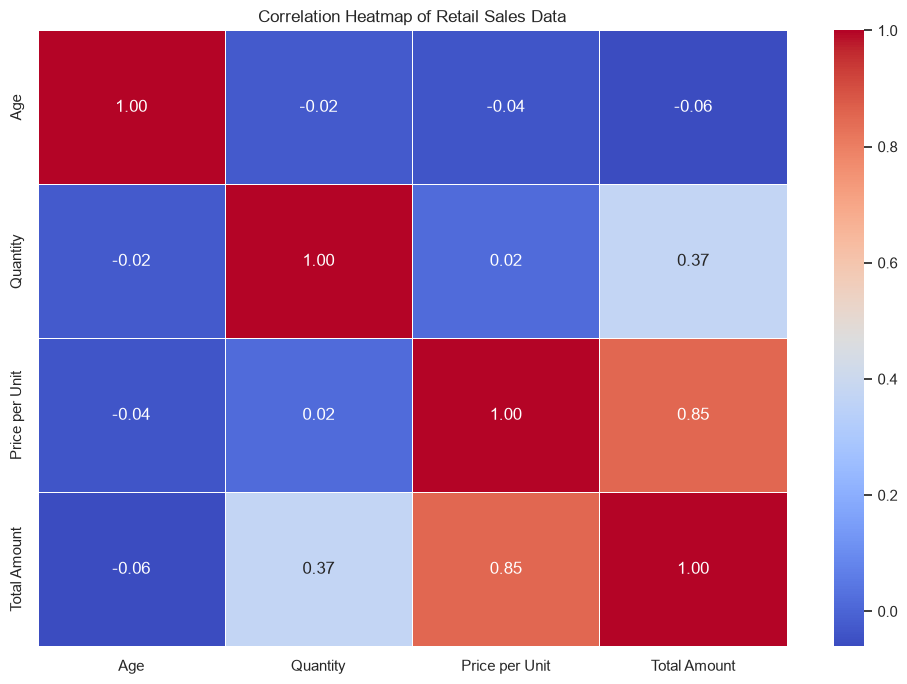

In [22]:
# Select numerical business variables
correlation_data = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

### Business Insights – Correlation Heatmap

1. Price per Unit and Total Amount have a strong positive
   correlation of 0.85.
2. Quantity and Total Amount show a moderate positive
   correlation of 0.37.
3. Age and Total Amount have a very weak negative
   correlation of -0.06.
4. Age and Quantity show almost no linear relationship.

### Business Interpretation

Product pricing has a stronger linear association
with transaction value than quantity in this dataset.
Customer age does not show a meaningful linear
relationship with transaction amount.

Correlation does not imply causation. Total Amount is
calculated using Quantity and Price per Unit, so
relationships with these variables are partly expected.

Revenue by Age Group

In [23]:
# Calculate revenue by age group
age_revenue = (
    df.groupby("Age Group", observed=False)
    .agg(
        Total_Revenue=("Total Amount", "sum"),
        Total_Transactions=("Transaction ID", "count"),
        Average_Transaction=("Total Amount", "mean")
    )
    .round(2)
    .reset_index()
)

display(age_revenue)

,Age Group,Total_Revenue,Total_Transactions,Average_Transaction
0,Below 18,11215,21,534.05
1,18-25,73335,148,495.51
2,26-35,98480,205,480.39
3,36-45,91870,202,454.80
4,46-55,100690,229,439.69
5,Above 55,80410,195,412.36


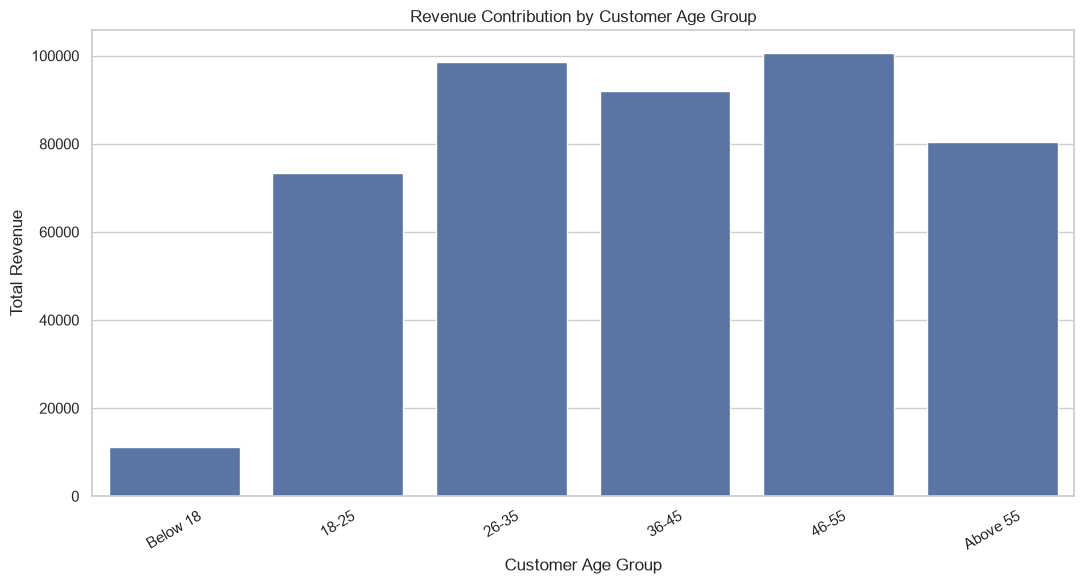

In [24]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=age_revenue,
    x="Age Group",
    y="Total_Revenue"
)

plt.title("Revenue Contribution by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Business Insights – Revenue by Customer Age Group

1. Customers aged 46-55 generated the highest revenue.
2. Customers aged 26-35 were the second-highest revenue group.
3. Customers aged 36-45 and above 55 also contributed
   significantly to total revenue.
4. Customers below 18 generated the lowest revenue.

### Business Interpretation

Middle-aged customers represent an important revenue
segment. The business should focus on customer retention
and targeted marketing for customers aged 26-55.

In [25]:
display(age_revenue)

,Age Group,Total_Revenue,Total_Transactions,Average_Transaction
0,Below 18,11215,21,534.05
1,18-25,73335,148,495.51
2,26-35,98480,205,480.39
3,36-45,91870,202,454.80
4,46-55,100690,229,439.69
5,Above 55,80410,195,412.36


In [26]:
print("Total Dataset Revenue:", df["Total Amount"].sum())
print("Total Age Group Revenue:", age_revenue["Total_Revenue"].sum())

Total Dataset Revenue: 456000
Total Age Group Revenue: 456000


In [27]:
# Correct age group boundaries
bins = [18, 26, 36, 46, 56, 101]

labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=False
)

# Recalculate age-group revenue
age_revenue = (
    df.groupby("Age Group", observed=False)
    .agg(
        Total_Revenue=("Total Amount", "sum"),
        Total_Transactions=("Transaction ID", "count"),
        Average_Transaction=("Total Amount", "mean")
    )
    .round(2)
    .reset_index()
)

display(age_revenue)

print("Total Revenue:", age_revenue["Total_Revenue"].sum())
print("Total Transactions:", age_revenue["Total_Transactions"].sum())

,Age Group,Total_Revenue,Total_Transactions,Average_Transaction
0,18-25,84550,169,500.30
1,26-35,98480,205,480.39
2,36-45,91870,202,454.80
3,46-55,100690,229,439.69
4,56+,80410,195,412.36


Total Revenue: 456000
Total Transactions: 1000


### Business Insights – Revenue by Customer Age Group

1. Customers aged 46-55 generated the highest revenue
   of 100,690.
2. Customers aged 26-35 generated 98,480.
3. The 46-55 age group recorded the highest transaction
   count with 229 transactions.
4. Customers aged 18-25 had the highest average
   transaction value of 500.30.
5. Customers aged 56+ generated 80,410.

### Business Interpretation

The 46-55 age group is the largest revenue contributor,
while younger adult customers aged 18-25 have a higher
average transaction value. The business should consider
different marketing and retention strategies for these
customer segments.

## Final Project Conclusion

The Retail Sales Exploratory Data Analysis project was conducted to understand sales performance, customer purchasing behaviour, and product category performance using Python.

The dataset contained 1,000 retail transactions and 9 columns. Initial data validation identified no missing values, duplicate records, invalid dates, or transaction amount mismatches.

### Key Findings

1. **Sales performance:** May 2023 recorded the highest monthly revenue of 53,150, while September 2023 recorded the lowest full-month revenue of 23,620.

2. **Quarterly performance:** Q4 2023 generated the highest quarterly revenue of 126,190.

3. **Customer demographics:** Customers aged 46–55 generated the highest revenue of 100,690 across 229 transactions.

4. **Gender analysis:** Female customers contributed 232,840 in revenue, compared with 223,160 from male customers.

5. **Product categories:** Electronics and Clothing were the leading revenue categories, while Beauty generated comparatively lower revenue.

6. **Correlation analysis:** Price per Unit showed a strong positive correlation of 0.85 with Total Amount. Quantity showed a moderate positive correlation of 0.37.

### Business Recommendations

- Develop customer retention and loyalty campaigns targeting customers aged 26–55.
- Maintain strong inventory availability for Electronics and Clothing while exploring promotional opportunities for Beauty.
- Investigate seasonal revenue fluctuations and use successful sales strategies to improve performance during weaker months.

### Limitations

The dataset does not contain individual product names, so individual top-10 product performance could not be evaluated. The currency is also unspecified. January 2024 contains only partial-period data in the available dataset.

### Conclusion

This project demonstrates how exploratory data analysis can transform raw retail transaction data into meaningful business insights. Python, Pandas, NumPy, Matplotlib, and Seaborn were used to perform data inspection, statistical analysis, visualization, and business interpretation.

The analysis provides a foundation for data-driven retail decisions and further customer and sales analytics.